[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/)

# Evaluación Parcial — Actividad 2: Red Neuronal Convolucional
## Clasificación del estado de salud de la colmena a partir de imágenes de abejas (BeeImage Dataset)

**Curso:** Ingeniería del Conocimiento (ISO56B) · Facultad de Ingeniería de Sistemas · UNCP
**Semestre:** 2026-II · **Fecha:** 21/10/2026
**Docente:** Msc. Jaime Antonio Huaytalla Pariona

---
## A. Presentación

### Integrantes
| N.° | Apellidos y nombres | Código |
|:---:|---|---|
| 1 | Quispe López, Joseph Saúl | 2024200202G |
| 2 | Quispe García, D'Alessandro Del Piero | 2024200201F |
| 3 | Hurtado Pastrana, Sebastián Katsari | 2024200189G |
| 4 | Quiroz Vílchez, Rony Esaú | 2024200200E |

### Dataset
- **Nombre:** The BeeImage Dataset: Annotated Honey Bee Images
- **Fuente:** Kaggle — https://www.kaggle.com/datasets/jenny18/honey-bee-annotated-images
- **Contenido:** 5,172 imágenes PNG de abejas obreras recortadas de videos de colmenas (EE. UU., julio–septiembre de 2018), más `bee_data.csv` con fecha, hora, ubicación, subespecie, salud, polen y casta de cada imagen.
- **Variable objetivo:** `health`, con 6 clases (healthy, few varrao/hive beetles, Varroa/Small Hive Beetles, ant problems, hive being robbed, missing queen).
- **Aprobación:** dataset aprobado por el docente.

**Justificación de la elección**
- **Relevancia:** las abejas son polinizadores clave para la producción de alimentos, y detectar a tiempo problemas en la colmena (varroa, escarabajos, robo) ayuda a los apicultores.

### Descripción del problema
Se entrena una CNN para clasificar en **6 categorías** el estado de salud de la colmena de origen a partir de la imagen de una abeja obrera. Es una clasificación multiclase con clases muy desbalanceadas, por lo que además de accuracy se reporta el **F1 macro**. La etiqueta describe a la **colmena**, no a la abeja individual, y cada grabación (ubicación + fecha + hora) tiene una sola etiqueta. Por eso el modelo podría aprender rasgos del video (fondo, iluminación) en lugar de signos de salud; esta limitación se analiza en las Secciones B, F y G.
### Contenido
**Paso A.** Entorno y requisitos · **B.** Carga, exploración y preprocesamiento · **C.** CNN Base · **D.** CNN Mejorada · **E.** Comparación de optimizadores · **F.** Evaluación rigurosa en test · **G.** Conclusiones

---
## Paso 0. Entorno de ejecución, datos y requisitos

In [ ]:
# Paso 0.1 — Verificar que Colab está usando la GPU
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'   # oculta mensajes informativos de TensorFlow
import tensorflow as tf

print('Versión de TensorFlow:', tf.__version__)
gpus = tf.config.list_physical_devices('GPU')
print('GPU detectada:', gpus if gpus else 'NINGUNA')
if not gpus:
    print('⚠ Activa la GPU: Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU T4\n'
          '  (en inglés: Runtime → Change runtime type → T4 GPU) y vuelve a ejecutar.')
!nvidia-smi -L

Versión de TensorFlow: 2.21.0
GPU detectada: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
GPU 0: Tesla T4 (UUID: GPU-acd9e3b2-2b72-e324-687e-8ad95e7cad75)


In [ ]:
# Paso 0.2 — Semillas fijas para que los resultados sean reproducibles
import random
import numpy as np

SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)  # hash interno de Python
random.seed(SEED)                          # módulo random de Python
np.random.seed(SEED)                       # NumPy (splits y barajado)
tf.random.set_seed(SEED)                   # TensorFlow (pesos iniciales, dropout, augmentation)
# Nota: en GPU algunas operaciones no son 100 % deterministas, así que las métricas
# pueden variar en décimas entre ejecuciones. tf.config.experimental.enable_op_determinism()
# lo evita, pero hace el entrenamiento más lento.
print('✓ Semillas fijadas en', SEED)

✓ Semillas fijadas en 42


In [ ]:
import glob
import os
import zipfile

ZIP_PATH = 'BeeImage Dataset.zip'  # <-- Nombre exacto con espacio
DATA_DIR = 'bee_dataset'  # Carpeta donde se descomprime

if not os.path.isdir(DATA_DIR):
  if not os.path.exists(ZIP_PATH):
    from google.colab import files

    files.upload()
  with zipfile.ZipFile(ZIP_PATH) as z:
    z.extractall(DATA_DIR)

# Se buscan las rutas automáticamente
CSV_PATH = glob.glob(
    os.path.join(DATA_DIR, '**', 'bee_data.csv'), recursive=True
)[0]
IMG_DIR = os.path.dirname(
    glob.glob(os.path.join(DATA_DIR, '**', '*.png'), recursive=True)[0]
)

print('CSV:     ', CSV_PATH)
print('Imágenes:', IMG_DIR)

Saving BeeImage Dataset.zip to BeeImage Dataset.zip
CSV:      bee_dataset/bee_data.csv
Imágenes: bee_dataset/bee_imgs/bee_imgs


In [ ]:
# Paso 0.4 — Validar los requisitos mínimos del dataset (Sección 2.2 de la consigna)
import pandas as pd
from PIL import Image

df = pd.read_csv(CSV_PATH)
en_disco = set(os.listdir(IMG_DIR))
faltantes = (~df['file'].isin(en_disco)).sum()   # filas del CSV sin imagen en disco
n_img, n_clases = len(df), df['health'].nunique()

requisitos = {
    '(a) Clasificación de imágenes (una etiqueta por imagen)': df['file'].is_unique,
    '(b) Al menos 1,000 imágenes':                            n_img >= 1000,
    '(c) Al menos 3 clases':                                  n_clases >= 3,
    'Todas las imágenes del CSV existen en disco':            faltantes == 0,
}
for req, ok in requisitos.items():
    print(f"{'✓' if ok else '✗'} {req}")
print(f'\nImágenes: {n_img} | Clases: {n_clases} | Faltantes: {faltantes}')
# (d) "datos reales" y (e) "no usado en clase / no es MNIST ni Fashion-MNIST"
#     no se comprueban con código: se justifican en la Sección A

✓ (a) Clasificación de imágenes (una etiqueta por imagen)
✓ (b) Al menos 1,000 imágenes
✓ (c) Al menos 3 clases
✓ Todas las imágenes del CSV existen en disco

Imágenes: 5172 | Clases: 6 | Faltantes: 0


In [ ]:
# Paso 0.5 — Modo de color: algunas imágenes traen canal alfa (RGBA)
# Al cargarlas se convertirán a RGB (3 canales) para que todas tengan la misma forma
modos = pd.Series([Image.open(os.path.join(IMG_DIR, f)).mode for f in df['file']])
print(modos.value_counts())

RGB     5141
RGBA      31
Name: count, dtype: int64


---
## B. Carga, exploración y preprocesamiento

In [ ]:
# B.1  Librerías y configuración de la sección
import time
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import ImageOps
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

plt.rcParams['figure.dpi'] = 100
sns.set_style('whitegrid')

IMG_SIZE = 64   # lado de la imagen cuadrada de entrada a la CNN (64 x 64 px)
CANALES = 3     # RGB

# Nombres cortos en español para los gráficos (las etiquetas originales no se modifican)
NOMBRES_CORTOS = {
    'healthy': 'Sana',
    'few varrao, hive beetles': 'Pocos varroa + escarabajos',
    'Varroa, Small Hive Beetles': 'Varroa + escarabajos',
    'ant problems': 'Hormigas',
    'hive being robbed': 'Robo de colmena',
    'missing queen': 'Sin reina',
}

In [ ]:
# B.2  Primer vistazo al archivo de anotaciones
display(df.head())
print(f'Filas: {df.shape[0]} | Columnas: {df.shape[1]}')
print('\nValores nulos por columna:\n', df.isna().sum())
print('\nDistribución de health (variable objetivo):')
print(df['health'].value_counts())

,file,date,time,location,zip code,subspecies,health,pollen_carrying,caste
0,041_066.png,8/28/18,16:07,"Alvin, TX, USA",77511,-1,hive being robbed,False,worker
1,041_072.png,8/28/18,16:07,"Alvin, TX, USA",77511,-1,hive being robbed,False,worker
2,041_073.png,8/28/18,16:07,"Alvin, TX, USA",77511,-1,hive being robbed,False,worker
3,041_067.png,8/28/18,16:07,"Alvin, TX, USA",77511,-1,hive being robbed,False,worker
4,041_059.png,8/28/18,16:07,"Alvin, TX, USA",77511,-1,hive being robbed,False,worker


Filas: 5172 | Columnas: 9

Valores nulos por columna:
 file               0
date               0
time               0
location           0
zip code           0
subspecies         0
health             0
pollen_carrying    0
caste              0
dtype: int64

Distribución de health (variable objetivo):
health
healthy                       3384
few varrao, hive beetles       579
Varroa, Small Hive Beetles     472
ant problems                   457
hive being robbed              251
missing queen                   29
Name: count, dtype: int64


In [ ]:
# B.3  Columnas que NO sirven como variable objetivo
print('caste:', df['caste'].value_counts().to_dict())                       # siempre "worker"
print('pollen_carrying:', df['pollen_carrying'].value_counts().to_dict())   # solo 18 True
print('subspecies = "-1" (dato faltante):', (df['subspecies'] == '-1').sum())
# caste tiene una sola clase y pollen_carrying apenas 18 casos positivos: no sirven como objetivo.
# subspecies tiene 428 faltantes codificados como "-1" (no como NaN). Por eso el objetivo es health.

caste: {'worker': 5172}
pollen_carrying: {False: 5154, True: 18}
subspecies = "-1" (dato faltante): 428


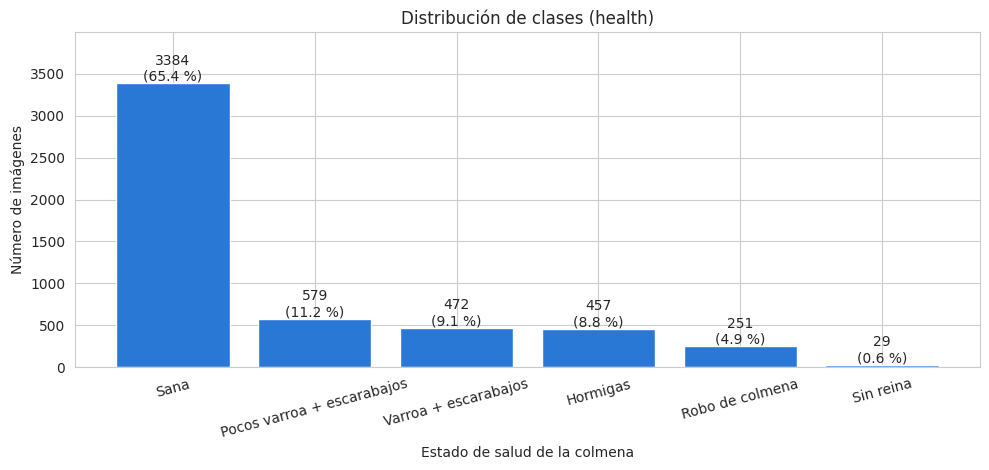

In [ ]:
# B.4  Distribución de la variable objetivo (conteo y porcentaje)
conteo = df['health'].value_counts()
porc = conteo / conteo.sum() * 100
etiquetas = [NOMBRES_CORTOS[c] for c in conteo.index]

fig, ax = plt.subplots(figsize=(10, 4.8))
barras = ax.bar(etiquetas, conteo.values, color='#2a78d6')
for b, n, p in zip(barras, conteo.values, porc.values):
    ax.text(b.get_x() + b.get_width() / 2, n + 30, f'{n}\n({p:.1f} %)', ha='center', fontsize=10)
ax.set_title('Distribución de clases (health)')
ax.set_xlabel('Estado de salud de la colmena')
ax.set_ylabel('Número de imágenes')
ax.set_ylim(0, conteo.max() * 1.18)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

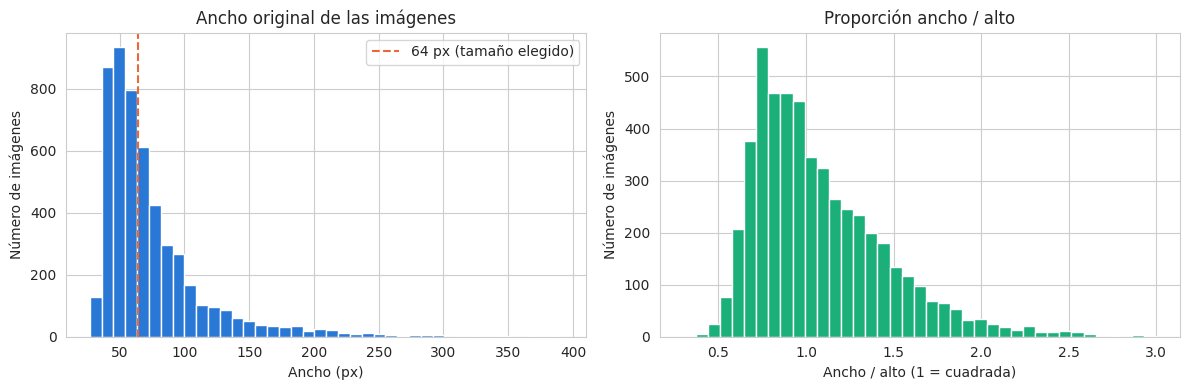

        count  mean   std   min   25%   50%   75%    max
ancho  5172.0  74.4  41.2  27.0  48.0  62.0  84.0  392.0
alto   5172.0  72.0  40.5  24.0  51.0  61.0  76.0  520.0

Imágenes con lado mayor ≤ 64 px: 40.8%
Imágenes con lado mayor ≤ 96 px: 79.5%


In [ ]:
# B.5  Tamaños originales: justifican el tamaño fijo elegido (64 x 64)
tamanos = np.array([Image.open(os.path.join(IMG_DIR, f)).size for f in df['file']])
df['ancho'], df['alto'] = tamanos[:, 0], tamanos[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df['ancho'], bins=40, color='#2a78d6', edgecolor='white')
axes[0].axvline(IMG_SIZE, color='#eb6834', linestyle='--', label=f'{IMG_SIZE} px (tamaño elegido)')
axes[0].set_title('Ancho original de las imágenes')
axes[0].set_xlabel('Ancho (px)')
axes[0].set_ylabel('Número de imágenes')
axes[0].legend()
axes[1].hist(df['ancho'] / df['alto'], bins=np.linspace(0.3, 3, 40), color='#1baf7a', edgecolor='white')
axes[1].set_title('Proporción ancho / alto')
axes[1].set_xlabel('Ancho / alto (1 = cuadrada)')
axes[1].set_ylabel('Número de imágenes')
plt.tight_layout()
plt.show()

print(df[['ancho', 'alto']].describe().round(1).T)
print(f"\nImágenes con lado mayor ≤ 64 px: {(df[['ancho', 'alto']].max(axis=1) <= 64).mean():.1%}")
print(f"Imágenes con lado mayor ≤ 96 px: {(df[['ancho', 'alto']].max(axis=1) <= 96).mean():.1%}")

**¿Por qué 64 × 64 con relleno?**
- La mediana del tamaño original es ≈ 62 × 61 px. Con 96 × 96, el 79.5 % de las imágenes se agrandaría por interpolación, lo que no agrega información real.
- 64 × 64 tiene 2.25 veces menos píxeles que 96 × 96: entrena más rápido en la T4 y deja menos parámetros después del `Flatten`, algo importante con solo 5 mil imágenes.
- La proporción ancho/alto varía entre ~0.6 y ~1.8. Estirar la imagen a un cuadrado deformaría el cuerpo de la abeja, así que se escala **manteniendo la proporción** y se rellena con negro.
- Desventaja: los ácaros varroa son puntos pequeños y a 64 px se pierde algo de detalle.

In [ ]:
# B.6  Carga de todas las imágenes: RGB + redimensionado con relleno a 64 x 64
def cargar_imagen(nombre_archivo):
    '''Abre una imagen, la pasa a RGB y la lleva a IMG_SIZE x IMG_SIZE sin deformarla.'''
    img = Image.open(os.path.join(IMG_DIR, nombre_archivo)).convert('RGB')   # RGBA -> RGB
    # ImageOps.pad escala manteniendo la proporción y rellena con negro lo que falte
    img = ImageOps.pad(img, (IMG_SIZE, IMG_SIZE), method=Image.Resampling.BICUBIC, color=(0, 0, 0))
    return np.asarray(img, dtype=np.uint8)

inicio = time.time()
X_all = np.stack([cargar_imagen(f) for f in df['file']])   # (N, 64, 64, 3), enteros 0–255
print(f'Imágenes cargadas: {X_all.shape} | dtype: {X_all.dtype} | {time.time() - inicio:.1f} s')

Imágenes cargadas: (5172, 64, 64, 3) | dtype: uint8 | 2.8 s


In [ ]:
# B.7  Codificación de las etiquetas a enteros (0..5)
encoder = LabelEncoder()
y_all = encoder.fit_transform(df['health'])   # texto -> entero
CLASES = list(encoder.classes_)               # orden alfabético que usa el encoder
CLASES_CORTAS = [NOMBRES_CORTOS[c] for c in CLASES]
NUM_CLASES = len(CLASES)

pd.DataFrame({'código': range(NUM_CLASES), 'clase original': CLASES,
              'nombre corto': CLASES_CORTAS, 'n imágenes': np.bincount(y_all)})

,código,clase original,nombre corto,n imágenes
0,0,"Varroa, Small Hive Beetles",Varroa + escarabajos,472
1,1,ant problems,Hormigas,457
2,2,"few varrao, hive beetles",Pocos varroa + escarabajos,579
3,3,healthy,Sana,3384
4,4,hive being robbed,Robo de colmena,251
5,5,missing queen,Sin reina,29


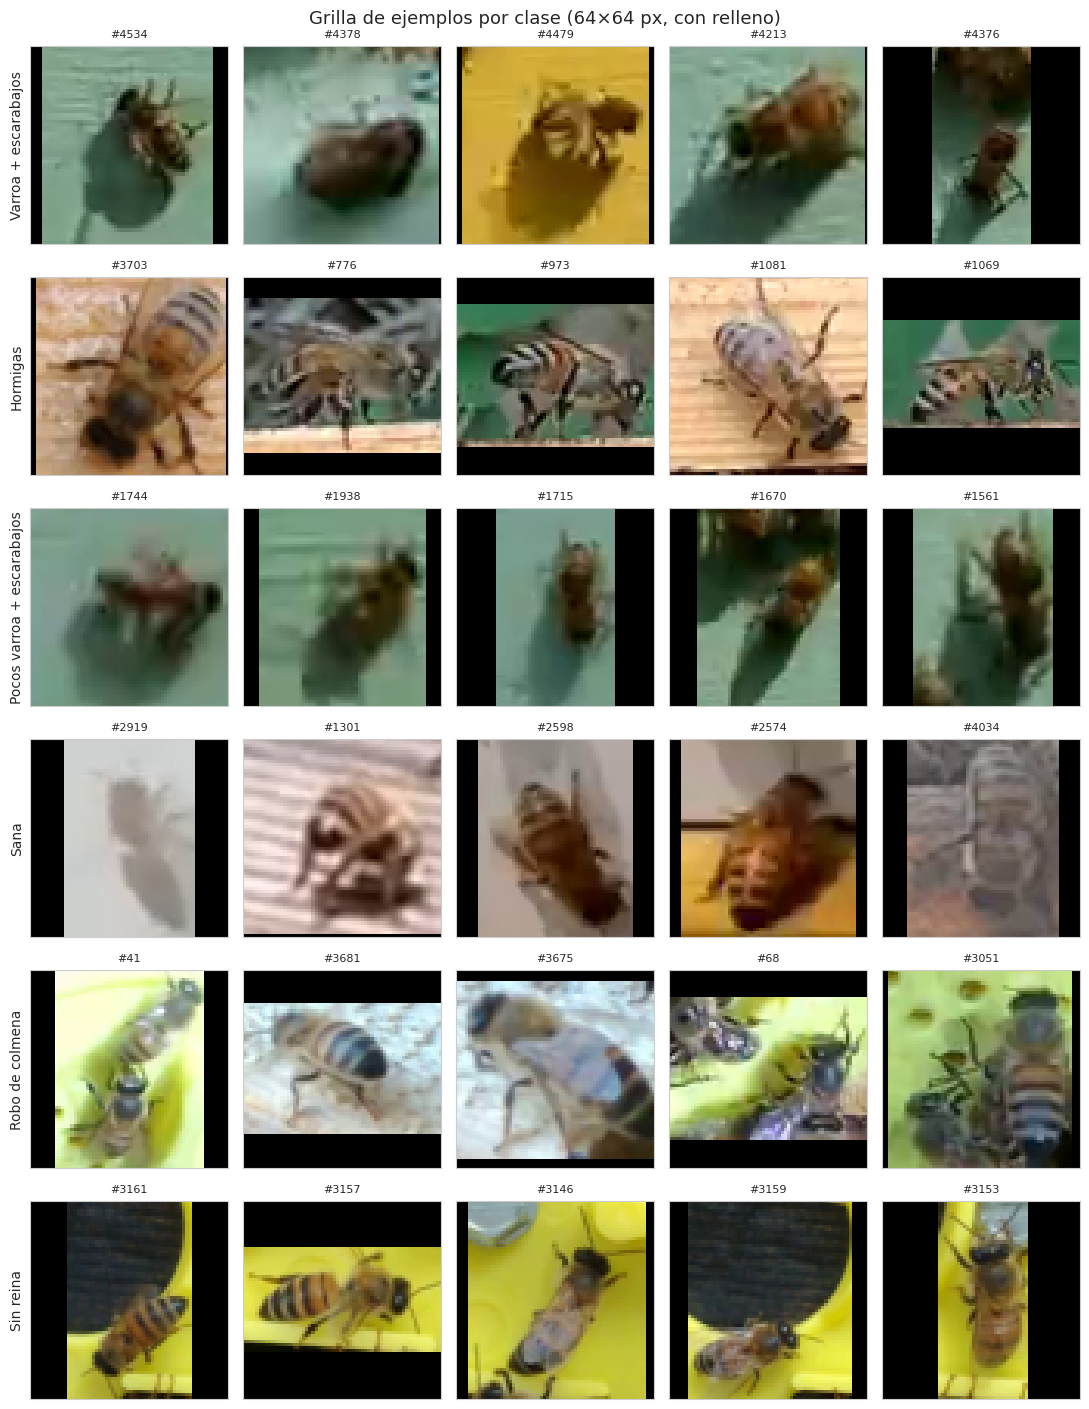

In [ ]:
# B.8  Grilla visual: 5 ejemplos de cada clase (imágenes ya en 64 x 64)
EJEMPLOS = 5
rng = np.random.default_rng(SEED)   # generador con semilla: la grilla siempre muestra las mismas
fig, axes = plt.subplots(NUM_CLASES, EJEMPLOS, figsize=(EJEMPLOS * 2.2, NUM_CLASES * 2.4))
for clase in range(NUM_CLASES):
    indices = rng.choice(np.where(y_all == clase)[0], EJEMPLOS, replace=False)
    for col, idx in enumerate(indices):
        ax = axes[clase, col]
        ax.imshow(X_all[idx])
        ax.set_xticks([]); ax.set_yticks([])
        ax.set_title(f'#{idx}', fontsize=8)
        if col == 0:
            ax.set_ylabel(CLASES_CORTAS[clase], fontsize=10)   # etiqueta de la fila = clase
plt.suptitle(f'Grilla de ejemplos por clase ({IMG_SIZE}×{IMG_SIZE} px, con relleno)', fontsize=13)
plt.tight_layout()
plt.show()

### Chequeo de posible fuga de información por grabación
Cada imagen es un cuadro recortado de un video. Si se agrupa por **ubicación + fecha + hora** (una grabación), se ve cuántas grabaciones originan cada clase y si una misma grabación mezcla etiquetas.

In [ ]:
# B.9  ¿Cuántas grabaciones hay por clase? ¿Alguna grabación tiene más de una etiqueta?
df['grabacion'] = df['location'] + ' | ' + df['date'] + ' | ' + df['time']
etiquetas_por_grab = df.groupby('grabacion')['health'].nunique()
print(f'Grabaciones distintas: {df["grabacion"].nunique()}')
print(f'Grabaciones con más de una etiqueta de salud: {(etiquetas_por_grab > 1).sum()}\n')

resumen_grab = (df.groupby('health')
                  .agg(imagenes=('file', 'size'), grabaciones=('grabacion', 'nunique'),
                       ubicaciones=('location', 'nunique'))
                  .sort_values('imagenes', ascending=False))
resumen_grab.index = [NOMBRES_CORTOS[c] for c in resumen_grab.index]
resumen_grab

Grabaciones distintas: 36
Grabaciones con más de una etiqueta de salud: 0



,imagenes,grabaciones,ubicaciones
Sana,3384,27,5
Pocos varroa + escarabajos,579,1,1
Varroa + escarabajos,472,1,1
Hormigas,457,2,1
Robo de colmena,251,4,1
Sin reina,29,1,1


In [ ]:
# B.10  Split estratificado: 80 % train+val / 20 % test, y luego 10 % del train para validación
idx_all = np.arange(len(df))   # se dividen índices para poder volver al CSV (fecha, ubicación)
idx_trainval, idx_test = train_test_split(
    idx_all, test_size=0.20, stratify=y_all, random_state=SEED)
idx_train, idx_val = train_test_split(
    idx_trainval, test_size=0.10, stratify=y_all[idx_trainval], random_state=SEED)

X_train, y_train = X_all[idx_train], y_all[idx_train]
X_val,   y_val   = X_all[idx_val],   y_all[idx_val]
X_test,  y_test  = X_all[idx_test],  y_all[idx_test]

# Verificación: la proporción de cada clase debe ser casi igual en los tres conjuntos
dist = pd.DataFrame({'Train': np.bincount(y_train, minlength=NUM_CLASES),
                     'Val':   np.bincount(y_val,   minlength=NUM_CLASES),
                     'Test':  np.bincount(y_test,  minlength=NUM_CLASES)}, index=CLASES_CORTAS)
dist.loc['TOTAL'] = dist.sum()
dist['% Train'] = (dist['Train'] / dist.loc['TOTAL', 'Train'] * 100).round(1)
dist['% Test'] = (dist['Test'] / dist.loc['TOTAL', 'Test'] * 100).round(1)
dist

,Train,Val,Test,% Train,% Test
Varroa + escarabajos,339,38,95,9.1,9.2
Hormigas,329,37,91,8.8,8.8
Pocos varroa + escarabajos,417,46,116,11.2,11.2
Sana,2436,271,677,65.4,65.4
Robo de colmena,181,20,50,4.9,4.8
Sin reina,21,2,6,0.6,0.6
TOTAL,3723,414,1035,100.0,100.0


In [ ]:
# B.11  Fuga tras el split: ¿cuántas imágenes de test vienen de una grabación que también está en train?
grab_train = set(df.loc[idx_train, 'grabacion'])
comparten = df.loc[idx_test, 'grabacion'].isin(grab_train).mean()
print(f'Imágenes de test cuya grabación también aparece en train: {comparten:.1%}')

Imágenes de test cuya grabación también aparece en train: 100.0%


In [ ]:
# B.12  Normalización de píxeles a [0, 1] y verificación de la forma (reshape)
X_train = X_train.astype('float32') / 255.0
X_val   = X_val.astype('float32') / 255.0
X_test  = X_test.astype('float32') / 255.0

# Conv2D espera (n_imágenes, alto, ancho, canales): las imágenes ya vienen así, no hace falta reshape
for nombre, X in [('train', X_train), ('val', X_val), ('test', X_test)]:
    assert X.shape[1:] == (IMG_SIZE, IMG_SIZE, CANALES)
    print(f'{nombre:5s}: {X.shape} | min = {X.min():.2f} | max = {X.max():.2f}')

train: (3723, 64, 64, 3) | min = 0.00 | max = 1.00
val  : (414, 64, 64, 3) | min = 0.00 | max = 1.00
test : (1035, 64, 64, 3) | min = 0.00 | max = 1.00


In [ ]:
# B.13  Resumen numérico final
INPUT_SHAPE = (IMG_SIZE, IMG_SIZE, CANALES)
print(f'Total de imágenes : {len(df)}')
print(f'Train             : {len(X_train)}  ({len(X_train) / len(df):.0%})')
print(f'Validación        : {len(X_val)}  ({len(X_val) / len(df):.0%})')
print(f'Test              : {len(X_test)}  ({len(X_test) / len(df):.0%})')
print(f'Shape de entrada  : {INPUT_SHAPE}  (alto, ancho, canales)')
print(f'Clases            : {NUM_CLASES} -> {CLASES_CORTAS}')
print(f'Memoria de X_train: {X_train.nbytes / 1e6:.0f} MB (float32)')

Total de imágenes : 5172
Train             : 3723  (72%)
Validación        : 414  (8%)
Test              : 1035  (20%)
Shape de entrada  : (64, 64, 3)  (alto, ancho, canales)
Clases            : 6 -> ['Varroa + escarabajos', 'Hormigas', 'Pocos varroa + escarabajos', 'Sana', 'Robo de colmena', 'Sin reina']
Memoria de X_train: 183 MB (float32)


### Conclusiones de la Sección B
- **Desbalance fuerte:** 65.4 % de las imágenes son "Sana" y "Sin reina" tiene solo 29 (en el split quedan 21 en train, 2 en validación y 6 en test). Por eso se reportarán **F1 macro** y métricas por clase, y se usará `class_weight`.
- **Preprocesamiento:** RGBA → RGB, redimensionado a 64 × 64 conservando la proporción (con relleno), píxeles normalizados a [0, 1] y etiquetas codificadas como enteros 0–5 (`sparse_categorical_crossentropy` no requiere one-hot).
- **Split:** estratificado 80/20 y luego 10 % del train para validación (3723 / 414 / 1035). Las proporciones de clase se mantienen en los tres conjuntos.
- **Fuga de información (limitación principal):** cada una de las 36 grabaciones tiene una sola etiqueta. Tres clases salen de **un único video** y el 100 % de las imágenes de test comparte grabación con el train. La grilla lo confirma a simple vista: las dos clases de varroa tienen fondo verdoso (Athens) y "Sin reina" / "Robo de colmena" tienen fondo amarillo (Alvin). La CNN podría aprender a reconocer **la grabación** (fondo, luz, cámara) y no la salud de la abeja, lo que inflaría las métricas de test. Un split agrupado por grabación no es posible: las clases con una sola grabación quedarían fuera del train o del test.

---
## C. CNN Base (sin regularización)

Arquitectura mínima: **3 bloques Conv2D + MaxPooling2D**, `Flatten`, una capa `Dense` oculta y la salida `softmax` con 6 neuronas. No lleva ninguna técnica de regularización (ni augmentation, ni BatchNorm, ni Dropout, ni L2), para poder medir después cuánto aportan.

In [ ]:
# C.1  Librerías de Keras y canal de datos con tf.data (batch + prefetch para usar bien la GPU)
from tensorflow.keras import layers, models, regularizers, callbacks, optimizers
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (classification_report, confusion_matrix, f1_score,
                             accuracy_score, balanced_accuracy_score, log_loss,
                             roc_curve, roc_auc_score)
from sklearn.preprocessing import label_binarize

BATCH_SIZE = 64
AUTOTUNE = tf.data.AUTOTUNE

def crear_dataset(X, y, barajar=False):
    '''Convierte arrays en un tf.data.Dataset por lotes; baraja solo el de entrenamiento.'''
    ds = tf.data.Dataset.from_tensor_slices((X, y))
    if barajar:
        ds = ds.shuffle(len(X), seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)   # prefetch: prepara el siguiente lote mientras la GPU entrena

ds_train = crear_dataset(X_train, y_train, barajar=True)
ds_val   = crear_dataset(X_val, y_val)
ds_test  = crear_dataset(X_test, y_test)
print(f'Lotes por época: train = {len(ds_train)}, val = {len(ds_val)}, test = {len(ds_test)}')

Lotes por época: train = 59, val = 7, test = 17


In [ ]:
# C.2  Pesos por clase para compensar el desbalance (inversamente proporcionales a su frecuencia)
pesos = compute_class_weight(class_weight='balanced', classes=np.arange(NUM_CLASES), y=y_train)
CLASS_WEIGHT = dict(enumerate(pesos))
pd.DataFrame({'clase': CLASES_CORTAS, 'n train': np.bincount(y_train),
              'peso': np.round(pesos, 2)})

,clase,n train,peso
0,Varroa + escarabajos,339,1.83
1,Hormigas,329,1.89
2,Pocos varroa + escarabajos,417,1.49
3,Sana,2436,0.25
4,Robo de colmena,181,3.43
5,Sin reina,21,29.55


**`class_weight` no es regularización:** solo multiplica la pérdida de cada imagen según su clase (un error en "Sin reina" pesa ~29 veces más que uno en "Sana"), para que el modelo no ignore a las clases minoritarias. Se usa **igual en todos los modelos**, así la comparación Base vs Mejorada mide solo el efecto de la regularización.

In [ ]:
# C.3  Funciones auxiliares: curvas de entrenamiento y métricas por conjunto
def plot_historia(historia, titulo):
    '''Grafica accuracy y loss de train vs validación por época.'''
    h = historia.history
    epocas = range(1, len(h['loss']) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
    axes[0].plot(epocas, h['accuracy'], 'o-', color='#2a78d6', markersize=4, label='Train')
    axes[0].plot(epocas, h['val_accuracy'], 's-', color='#eb6834', markersize=4, label='Validación')
    axes[0].set_title(f'Accuracy — {titulo}')
    axes[0].set_xlabel('Época')
    axes[0].set_ylabel('Accuracy')
    axes[0].legend()
    axes[1].plot(epocas, h['loss'], 'o-', color='#2a78d6', markersize=4, label='Train')
    axes[1].plot(epocas, h['val_loss'], 's-', color='#eb6834', markersize=4, label='Validación')
    axes[1].set_title(f'Loss — {titulo}')
    axes[1].set_xlabel('Época')
    axes[1].set_ylabel('Loss (entropía cruzada)')
    axes[1].legend()
    plt.tight_layout()
    plt.show()


def evaluar_conjunto(modelo, X, y):
    '''Accuracy, loss (entropía cruzada SIN el término L2) y F1 macro sobre un conjunto.'''
    proba = modelo.predict(X, batch_size=256, verbose=0)
    pred = proba.argmax(axis=1)
    return {'accuracy': accuracy_score(y, pred),
            'loss': log_loss(y, proba, labels=np.arange(NUM_CLASES)),
            'f1_macro': f1_score(y, pred, average='macro')}

print('✓ Funciones auxiliares: crear_dataset, plot_historia, evaluar_conjunto')

✓ Funciones auxiliares: crear_dataset, plot_historia, evaluar_conjunto


In [ ]:
# C.4  Definición de la CNN Base
def construir_cnn_base():
    '''3 bloques Conv2D + MaxPooling2D, Flatten, Dense oculta y salida softmax. Sin regularización.'''
    modelo = models.Sequential([
        layers.Input(shape=INPUT_SHAPE),
        # Bloque 1: 32 filtros 3x3; padding='same' conserva el tamaño 64x64 antes del pooling
        layers.Conv2D(32, (3, 3), padding='same', activation='relu'),
        layers.MaxPooling2D((2, 2)),                     # 64x64 -> 32x32
        # Bloque 2
        layers.Conv2D(64, (3, 3), padding='same', activation='relu'),
        layers.MaxPooling2D((2, 2)),                     # 32x32 -> 16x16
        # Bloque 3
        layers.Conv2D(128, (3, 3), padding='same', activation='relu'),
        layers.MaxPooling2D((2, 2)),                     # 16x16 -> 8x8
        # Clasificador
        layers.Flatten(),                                # 8 x 8 x 128 = 8192 valores
        layers.Dense(128, activation='relu'),
        layers.Dense(NUM_CLASES, activation='softmax'),  # una probabilidad por clase
    ], name='cnn_base')
    modelo.compile(optimizer=optimizers.Adam(learning_rate=1e-3),
                   loss='sparse_categorical_crossentropy',   # etiquetas enteras 0..5
                   metrics=['accuracy'])
    return modelo

tf.keras.utils.set_random_seed(SEED)   # mismos pesos iniciales en cada ejecución
cnn_base = construir_cnn_base()
cnn_base.summary()

Model: "cnn_base"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     1,048,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,142,726 (4.36 MB)

 Trainable params: 1,142,726 (4.36 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# C.5  ¿Dónde se concentran los parámetros?
def parametros_por_capa(modelo):
    '''Tabla con los parámetros de cada capa y su porcentaje sobre el total.'''
    filas = [{'capa': c.name, 'tipo': c.__class__.__name__, 'parámetros': c.count_params()}
             for c in modelo.layers if c.count_params() > 0]
    tabla = pd.DataFrame(filas)
    tabla['% del total'] = (tabla['parámetros'] / tabla['parámetros'].sum() * 100).round(1)
    return tabla

tabla_param_base = parametros_por_capa(cnn_base)
display(tabla_param_base)
print(f'Total de parámetros: {cnn_base.count_params():,}')
por_tipo = tabla_param_base.groupby('tipo')['parámetros'].sum()
print(f"Capas Dense: {por_tipo.get('Dense', 0) / cnn_base.count_params():.1%} del total "
      f"| Capas Conv2D: {por_tipo.get('Conv2D', 0) / cnn_base.count_params():.1%}")

,capa,tipo,parámetros,% del total
0,conv2d,Conv2D,896,0.1
1,conv2d_1,Conv2D,18496,1.6
2,conv2d_2,Conv2D,73856,6.5
3,dense,Dense,1048704,91.8
4,dense_1,Dense,774,0.1


Total de parámetros: 1,142,726
Capas Dense: 91.8% del total | Capas Conv2D: 8.2%


In [ ]:
# C.6  Entrenamiento de la CNN Base (20 épocas, sin callbacks)
EPOCAS_BASE = 20
inicio = time.time()
hist_base = cnn_base.fit(ds_train, validation_data=ds_val, epochs=EPOCAS_BASE,
                         class_weight=CLASS_WEIGHT, verbose=2)
tiempo_base = time.time() - inicio
print(f'\nTiempo de entrenamiento: {tiempo_base:.0f} s')

Epoch 1/20
59/59 - 16s - 275ms/step - accuracy: 0.4002 - loss: 1.4004 - val_accuracy: 0.6473 - val_loss: 1.0161
Epoch 2/20
59/59 - 1s - 15ms/step - accuracy: 0.6543 - loss: 0.7432 - val_accuracy: 0.6787 - val_loss: 0.8215
Epoch 3/20
59/59 - 1s - 13ms/step - accuracy: 0.7647 - loss: 0.4953 - val_accuracy: 0.6691 - val_loss: 0.7853
Epoch 4/20
59/59 - 1s - 13ms/step - accuracy: 0.8069 - loss: 0.4812 - val_accuracy: 0.7971 - val_loss: 0.5459
Epoch 5/20
59/59 - 1s - 13ms/step - accuracy: 0.8227 - loss: 0.3772 - val_accuracy: 0.8744 - val_loss: 0.4032
Epoch 6/20
59/59 - 1s - 13ms/step - accuracy: 0.8660 - loss: 0.2972 - val_accuracy: 0.8019 - val_loss: 0.5791
Epoch 7/20
59/59 - 1s - 13ms/step - accuracy: 0.8767 - loss: 0.2749 - val_accuracy: 0.8865 - val_loss: 0.3155
Epoch 8/20
59/59 - 1s - 12ms/step - accuracy: 0.9041 - loss: 0.2178 - val_accuracy: 0.8309 - val_loss: 0.4289
Epoch 9/20
59/59 - 1s - 14ms/step - accuracy: 0.9095 - loss: 0.2060 - val_accuracy: 0.8865 - val_loss: 0.2893
Epoch 10

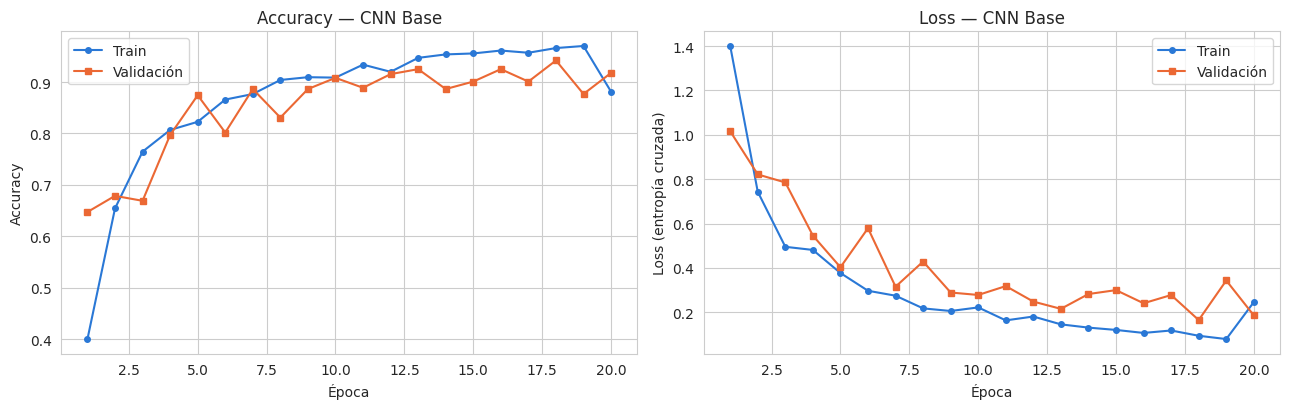

In [ ]:
# C.7  Curvas de accuracy y loss (train vs validación)
plot_historia(hist_base, 'CNN Base')

In [ ]:
# C.8  Números para el diagnóstico de overfitting
h = hist_base.history
mejor_ep = int(np.argmin(h['val_loss'])) + 1
print(f"Última época  -> acc train: {h['accuracy'][-1]:.3f} | acc val: {h['val_accuracy'][-1]:.3f} "
      f"| brecha: {h['accuracy'][-1] - h['val_accuracy'][-1]:+.3f}")
print(f"                 loss train: {h['loss'][-1]:.3f} | loss val: {h['val_loss'][-1]:.3f}")
print(f'Menor val_loss en la época {mejor_ep} ({min(h["val_loss"]):.3f}); '
      f'después la val_loss sube {h["val_loss"][-1] / min(h["val_loss"]):.1f} veces')

Última época  -> acc train: 0.881 | acc val: 0.918 | brecha: -0.037
                 loss train: 0.246 | loss val: 0.186
Menor val_loss en la época 18 (0.165); después la val_loss sube 1.1 veces


### Diagnóstico de overfitting — CNN Base
La CNN Base aprende muy rápido: la accuracy de entrenamiento sube de 0.40 a ~0.94–0.97 en 20 épocas. La de validación sube hasta ~0.92 hacia la época 13 y después **deja de mejorar** y oscila entre 0.85 y 0.93. La señal más clara está en la **loss**: la de train sigue bajando hasta el final, mientras que la val_loss toca su mínimo en la **época 13 (0.19)** y luego sube y oscila, con picos de 0.42 y 0.26 en la última época. Evaluada en modo inferencia (tabla D.7), la brecha es de **0.975 vs 0.913 en accuracy (6.2 puntos)** y de **0.074 vs 0.260 en loss (3.5 veces mayor en validación)**. Conclusión: hay **sobreajuste moderado** a partir de la época ~13: el modelo sigue memorizando el train sin ganar en validación. Es esperable, porque el **92 % de sus 1.14 millones de parámetros** está en la capa `Dense` que sigue al `Flatten`, el lugar donde más fácilmente se memorizan detalles. Advertencia: aunque la val accuracy sea alta, la validación comparte grabaciones con el train (B.11), así que no prueba que el modelo reconozca la salud de la abeja.

---
## D. CNN Mejorada (con regularización)

| Técnica | Dónde | Qué hace |
|---|---|---|
| **Data Augmentation** | primera capa del modelo | Crea variaciones geométricas aleatorias de cada imagen en cada época (solo en entrenamiento). |
| **BatchNormalization** | después de cada Conv2D, **antes** de ReLU | Normaliza las activaciones de cada lote: entrenamiento más estable y algo de regularización. |
| **Dropout** | tras los bloques 3 y 4 (0.1 y 0.2) y tras el GAP (0.3) | Apaga neuronas al azar: obliga a no depender de unas pocas. |
| **GlobalAveragePooling2D** | en lugar de `Flatten` | Promedia cada mapa de activación: 256 valores en vez de miles, muchos menos parámetros. |
| **Regularización L2** | pesos de Conv2D y Dense (λ = 1e-4) | Penaliza pesos grandes en la pérdida. |
| **EarlyStopping** + **ReduceLROnPlateau** | callbacks | Detiene el entrenamiento cuando la validación deja de mejorar y reduce el learning rate al estancarse. |

**Nota de diseño (prueba previa):** una primera versión con augmentation de **brillo y contraste**, más dropout (0.2/0.3/0.4/0.3) y BatchNorm con `momentum=0.99` quedó **subajustada**: accuracy de train ≈ 0.86, de validación ≈ 0.85 y una val_loss muy inestable. Se corrigió quitando brillo y contraste, bajando el dropout y usando `momentum=0.9` en BatchNorm. Como se cambiaron varias cosas a la vez, no se puede atribuir la mejora a una sola de ellas.

In [ ]:
# D.1  Capa de Data Augmentation (solo actúa con training=True, es decir, durante fit)
def crear_aumento():
    '''Transformaciones geométricas aleatorias que no cambian la clase de la imagen.'''
    return models.Sequential([
        layers.RandomFlip('horizontal_and_vertical', seed=SEED),        # espejo
        layers.RandomRotation(0.25, fill_mode='constant', seed=SEED),   # giro de hasta ±90°
        layers.RandomZoom(0.1, fill_mode='constant', seed=SEED),        # acercar/alejar ±10 %
    ], name='data_augmentation')

aumento_demo = crear_aumento()
print('✓ Capa de augmentation definida')

✓ Capa de augmentation definida


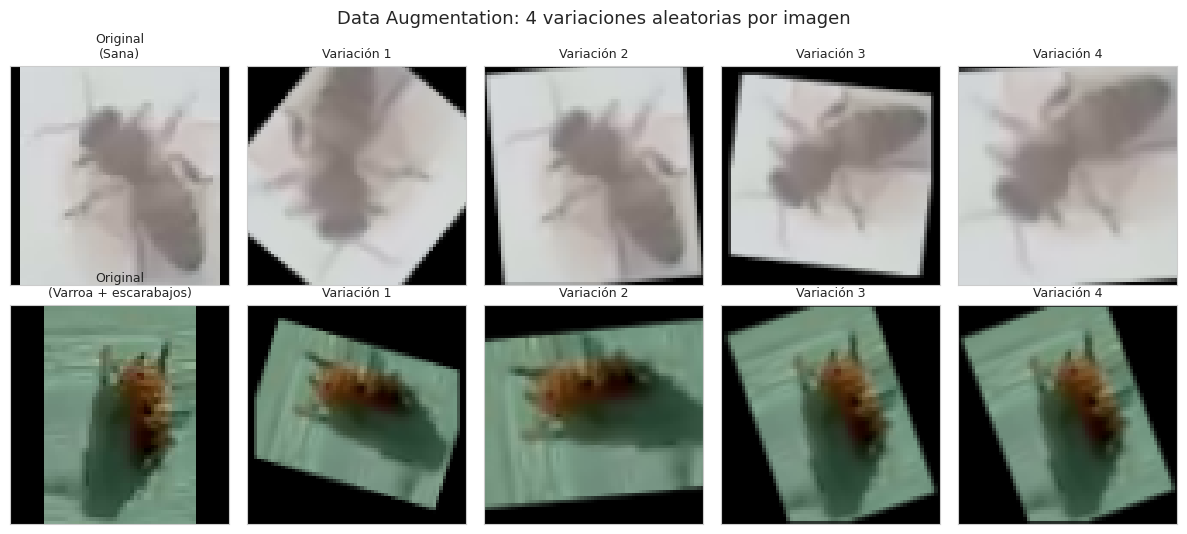

In [ ]:
# D.2  Visualización: 4 variaciones aleatorias de dos imágenes de train
ejemplos = [int(np.where(y_train == c)[0][0]) for c in (CLASES_CORTAS.index('Sana'),
                                                         CLASES_CORTAS.index('Varroa + escarabajos'))]
fig, axes = plt.subplots(len(ejemplos), 5, figsize=(12, 5.4))
for fila, i in enumerate(ejemplos):
    axes[fila, 0].imshow(X_train[i])
    axes[fila, 0].set_title(f'Original\n({CLASES_CORTAS[y_train[i]]})', fontsize=9)
    for col in range(1, 5):
        variada = aumento_demo(X_train[i][None, ...], training=True)[0].numpy()
        axes[fila, col].imshow(np.clip(variada, 0, 1))
        axes[fila, col].set_title(f'Variación {col}', fontsize=9)
for ax in axes.ravel():
    ax.set_xticks([]); ax.set_yticks([])
plt.suptitle('Data Augmentation: 4 variaciones aleatorias por imagen', fontsize=13)
plt.tight_layout()
plt.show()

**¿Por qué estas transformaciones tienen sentido para imágenes de abejas?**
- **Giros y espejos:** las abejas se graban desde arriba mientras caminan en la entrada de la colmena, en cualquier dirección. Una abeja girada 90° o reflejada sigue siendo la misma abeja con el mismo estado de salud, así que el modelo debe ser invariante a la orientación.
- **Zoom ±10 %:** los recortes del video tienen tamaños muy distintos (de 24 a 520 px); acercar o alejar un poco simula esa variación.
- **Lo que NO se aplica: brillo, contraste ni tono.** El color sí es informativo (los ácaros varroa son puntos rojizos sobre el cuerpo). Además, en la prueba previa variar brillo y contraste dejó al modelo subajustado. Ojo con la lectura: parte de la "información" del color e iluminación es la fuga por grabación (ver F.7), así que una accuracy más alta sin esas transformaciones **no garantiza** que el modelo generalice mejor a colmenas nuevas.

In [ ]:
# D.3  Definición de la CNN Mejorada
L2 = 1e-4   # fuerza de la regularización L2

def bloque_conv(filtros, dropout=0.0):
    '''Conv2D (sin activación) -> BatchNorm -> ReLU -> MaxPooling (+ Dropout opcional).'''
    capas = [
        # use_bias=False: BatchNorm ya tiene su propio desplazamiento (beta), el sesgo sobraría
        layers.Conv2D(filtros, (3, 3), padding='same', use_bias=False,
                      kernel_regularizer=regularizers.l2(L2)),
        # normaliza ANTES de la activación; momentum=0.9 (en vez de 0.99) hace que las
        # medias móviles usadas en validación sigan más rápido a los pesos y la val_loss no salte
        layers.BatchNormalization(momentum=0.9),
        layers.Activation('relu'),
        layers.MaxPooling2D((2, 2)),
    ]
    if dropout > 0:
        capas.append(layers.Dropout(dropout))
    return capas

def construir_cnn_mejorada(optimizador):
    '''CNN con augmentation, BatchNorm, Dropout, GlobalAveragePooling2D y L2.'''
    modelo = models.Sequential([
        layers.Input(shape=INPUT_SHAPE),
        crear_aumento(),                       # solo activa durante el entrenamiento
        *bloque_conv(32),                      # 64 -> 32
        *bloque_conv(64),                      # 32 -> 16
        *bloque_conv(128, dropout=0.1),        # 16 -> 8
        *bloque_conv(256, dropout=0.2),        # 8 -> 4
        layers.GlobalAveragePooling2D(),       # 4 x 4 x 256 -> 256 (promedio por mapa)
        layers.Dropout(0.3),
        layers.Dense(64, activation='relu', kernel_regularizer=regularizers.l2(L2)),
        layers.Dense(NUM_CLASES, activation='softmax'),
    ], name='cnn_mejorada')
    modelo.compile(optimizer=optimizador, loss='sparse_categorical_crossentropy',
                   metrics=['accuracy'])
    return modelo

tf.keras.utils.set_random_seed(SEED)
cnn_mejorada = construir_cnn_mejorada(optimizers.Adam(learning_rate=1e-3))
cnn_mejorada.summary()

Model: "cnn_mejorada"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 64, 64, 32)     │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 16, 16, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 8, 8, 256)      │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 8, 8, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │        16,448 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 406,694 (1.55 MB)

 Trainable params: 405,734 (1.55 MB)

 Non-trainable params: 960 (3.75 KB)

In [ ]:
# D.4  Parámetros: CNN Base vs CNN Mejorada
tabla_param_mej = parametros_por_capa(cnn_mejorada)
display(tabla_param_mej)
print(f'CNN Base:     {cnn_base.count_params():>9,} parámetros')
print(f'CNN Mejorada: {cnn_mejorada.count_params():>9,} parámetros '
      f'({cnn_mejorada.count_params() / cnn_base.count_params():.0%} de la Base)')

,capa,tipo,parámetros,% del total
0,conv2d_3,Conv2D,864,0.2
1,batch_normalization,BatchNormalization,128,0.0
2,conv2d_4,Conv2D,18432,4.5
3,batch_normalization_1,BatchNormalization,256,0.1
4,conv2d_5,Conv2D,73728,18.1
5,batch_normalization_2,BatchNormalization,512,0.1
6,conv2d_6,Conv2D,294912,72.5
7,batch_normalization_3,BatchNormalization,1024,0.3
8,dense_2,Dense,16448,4.0
9,dense_3,Dense,390,0.1


CNN Base:     1,142,726 parámetros
CNN Mejorada:   406,694 parámetros (36% de la Base)


In [ ]:
# D.5  Callbacks y entrenamiento de la CNN Mejorada
EPOCAS_MAX = 60   # máximo; EarlyStopping lo detendrá antes si la validación deja de mejorar
lista_callbacks = [
    # Detiene si val_loss no mejora en 12 épocas y RECUPERA los pesos de la mejor época
    callbacks.EarlyStopping(monitor='val_loss', patience=12, restore_best_weights=True, verbose=1),
    # Si val_loss se estanca 3 épocas, divide el learning rate entre 2
    callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6, verbose=1),
]

inicio = time.time()
hist_mej = cnn_mejorada.fit(ds_train, validation_data=ds_val, epochs=EPOCAS_MAX,
                            class_weight=CLASS_WEIGHT, callbacks=lista_callbacks, verbose=2)
tiempo_mej = time.time() - inicio
print(f'\nÉpocas entrenadas: {len(hist_mej.history["loss"])} | Tiempo: {tiempo_mej:.0f} s')

Epoch 1/60
59/59 - 10s - 167ms/step - accuracy: 0.5786 - loss: 1.0115 - val_accuracy: 0.7271 - val_loss: 0.7181 - learning_rate: 0.0010
Epoch 2/60
59/59 - 2s - 30ms/step - accuracy: 0.7193 - loss: 0.6407 - val_accuracy: 0.7101 - val_loss: 0.7813 - learning_rate: 0.0010
Epoch 3/60
59/59 - 2s - 30ms/step - accuracy: 0.7317 - loss: 0.6828 - val_accuracy: 0.4348 - val_loss: 1.7151 - learning_rate: 0.0010
Epoch 4/60

Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
59/59 - 2s - 29ms/step - accuracy: 0.7883 - loss: 0.5159 - val_accuracy: 0.5580 - val_loss: 1.1627 - learning_rate: 0.0010
Epoch 5/60
59/59 - 3s - 44ms/step - accuracy: 0.8308 - loss: 0.4246 - val_accuracy: 0.7657 - val_loss: 0.6221 - learning_rate: 5.0000e-04
Epoch 6/60
59/59 - 2s - 29ms/step - accuracy: 0.8396 - loss: 0.3964 - val_accuracy: 0.8599 - val_loss: 0.3791 - learning_rate: 5.0000e-04
Epoch 7/60
59/59 - 2s - 29ms/step - accuracy: 0.8501 - loss: 0.3932 - val_accuracy: 0.8043 - val_loss: 0.5576

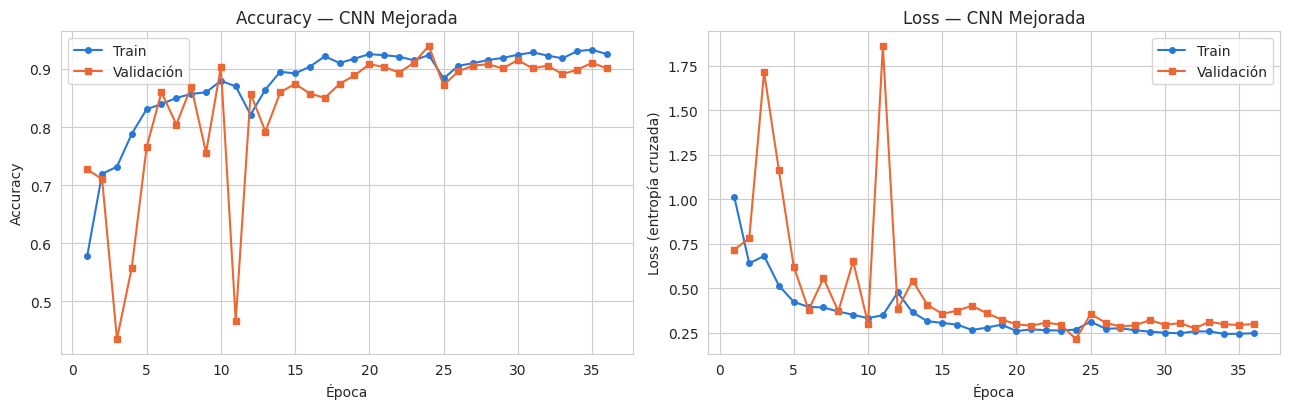

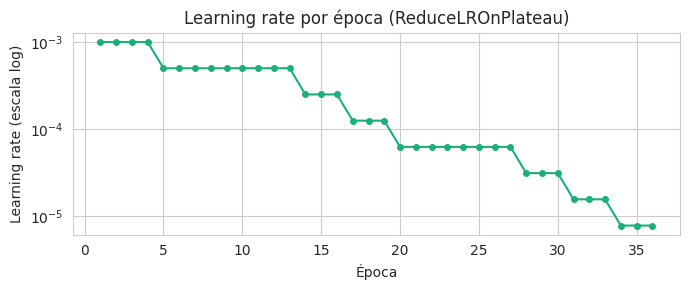

In [ ]:
# D.6  Curvas de accuracy y loss de la CNN Mejorada + evolución del learning rate
plot_historia(hist_mej, 'CNN Mejorada')

if 'learning_rate' in hist_mej.history:
    fig, ax = plt.subplots(figsize=(7, 3))
    ax.plot(range(1, len(hist_mej.history['learning_rate']) + 1), hist_mej.history['learning_rate'],
            'o-', color='#1baf7a', markersize=4)
    ax.set_yscale('log')
    ax.set_title('Learning rate por época (ReduceLROnPlateau)')
    ax.set_xlabel('Época')
    ax.set_ylabel('Learning rate (escala log)')
    plt.tight_layout()
    plt.show()

In [ ]:
# D.7  Comparación cuantitativa: CNN Base vs CNN Mejorada
# Se evalúa en modo inferencia (sin augmentation ni dropout) sobre train y validación;
# la loss es la entropía cruzada pura (sin el término L2), para comparar en igualdad de condiciones.
filas = []
for nombre, modelo, hist, seg in [('CNN Base', cnn_base, hist_base, tiempo_base),
                                  ('CNN Mejorada', cnn_mejorada, hist_mej, tiempo_mej)]:
    tr = evaluar_conjunto(modelo, X_train, y_train)
    va = evaluar_conjunto(modelo, X_val, y_val)
    filas.append({'Modelo': nombre, 'Parámetros': modelo.count_params(),
                  'Épocas': len(hist.history['loss']), 'Tiempo (s)': round(seg),
                  'Acc train': tr['accuracy'], 'Acc val': va['accuracy'],
                  'Brecha acc (train − val)': tr['accuracy'] - va['accuracy'],
                  'Loss train': tr['loss'], 'Loss val': va['loss'],
                  'Brecha loss (val − train)': va['loss'] - tr['loss'],
                  'F1 macro val': va['f1_macro']})
comparacion_bm = pd.DataFrame(filas).set_index('Modelo').round(3)
comparacion_bm

,Parámetros,Épocas,Tiempo (s),Acc train,Acc val,Brecha acc (train − val),Loss train,Loss val,Brecha loss (val − train),F1 macro val
Modelo,,,,,,,,,,
CNN Base,1142726,20,32,0.973,0.918,0.055,0.085,0.186,0.101,0.877
CNN Mejorada,406694,36,72,0.927,0.940,-0.013,0.170,0.171,0.000,0.908


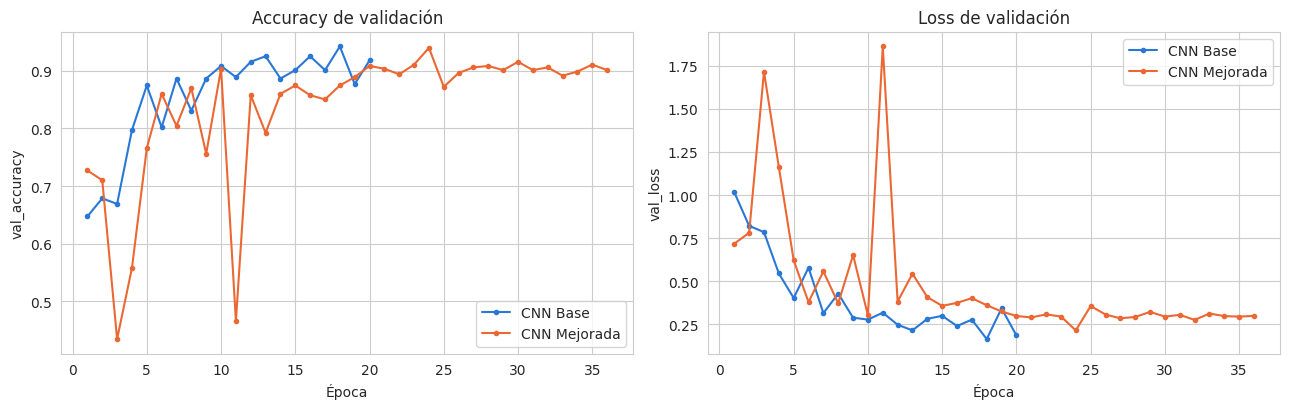

In [ ]:
# D.8  Validación de ambos modelos en un mismo gráfico
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for hist, nombre, color in [(hist_base, 'CNN Base', '#2a78d6'), (hist_mej, 'CNN Mejorada', '#eb6834')]:
    ep = range(1, len(hist.history['loss']) + 1)
    axes[0].plot(ep, hist.history['val_accuracy'], 'o-', markersize=3, color=color, label=nombre)
    axes[1].plot(ep, hist.history['val_loss'], 'o-', markersize=3, color=color, label=nombre)
axes[0].set_title('Accuracy de validación')
axes[0].set_xlabel('Época')
axes[0].set_ylabel('val_accuracy')
axes[0].legend()
axes[1].set_title('Loss de validación')
axes[1].set_xlabel('Época')
axes[1].set_ylabel('val_loss')
axes[1].legend()
plt.tight_layout()
plt.show()

### ¿Mejoró? ¿Se redujo el overfitting?
- **El overfitting prácticamente desapareció:** la brecha de accuracy pasó de **0.062 a 0.003** y la de loss de **0.186 a 0.007**. Las curvas de train y validación de la CNN Mejorada van casi juntas al final del entrenamiento.
- **Mejoró un poco la validación:** accuracy de **0.913 a 0.923** (+1 punto) y loss de **0.260 a 0.166** (−36 %). Una loss menor significa probabilidades mejor calibradas: el modelo se equivoca con menos seguridad.
- **El F1 macro de validación quedó igual** (0.891 vs 0.885). Es una métrica ruidosa en validación, porque "Sin reina" tiene solo 2 imágenes y "Robo de colmena" 20.
- **Usa 64 % menos parámetros** (1.14 M → 0.41 M): el `GlobalAveragePooling2D` elimina la capa `Dense` de 1.05 M parámetros que tenía la Base.
- **Costo:** necesitó 36 épocas en lugar de 20 y unas 4 veces más tiempo, porque el augmentation y BatchNorm hacen más lenta cada época. EarlyStopping se detuvo en la época 36 y **restauró los pesos de la época 24** (menor val_loss). ReduceLROnPlateau bajó el learning rate 7 veces (de 1e-3 a ~8e-6) y estabilizó las últimas épocas. Al inicio la validación es inestable (cae a 0.57 en la época 3), algo habitual mientras se ajustan las estadísticas de BatchNorm.

La regularización cumplió su objetivo principal, **cerrar la brecha de generalización**, pero la accuracy subió poco. Una explicación probable es que la Base ya aprovechaba las pistas de fondo e iluminación que comparten train y validación (misma grabación), y ninguna técnica de regularización corrige una fuga de información.

---
## E. Comparación de optimizadores

Se entrena **la misma arquitectura** (CNN Mejorada), con los mismos pesos iniciales (misma semilla) y **20 épocas fijas sin callbacks**, cambiando solo el optimizador:
- **Adam** (lr = 0.001): adapta un learning rate por parámetro usando el promedio del gradiente (momento) y de su cuadrado.
- **SGD con momentum** (lr = 0.01, momentum = 0.9): descenso de gradiente clásico con "inercia" que acumula la dirección de los pasos anteriores.
- **RMSprop** (lr = 0.001): divide el paso por la raíz del promedio reciente del gradiente al cuadrado.

Sin callbacks, todos reciben el mismo presupuesto de épocas y las curvas muestran la velocidad de convergencia real de cada uno.

In [ ]:
# E.1  Entrenamiento de la misma arquitectura con 3 optimizadores
EPOCAS_OPT = 20
config_opt = {
    'Adam':           lambda: optimizers.Adam(learning_rate=1e-3),
    'SGD + momentum': lambda: optimizers.SGD(learning_rate=1e-2, momentum=0.9),
    'RMSprop':        lambda: optimizers.RMSprop(learning_rate=1e-3),
}
historias_opt, tiempos_opt = {}, {}
for nombre, crear_opt in config_opt.items():
    tf.keras.utils.set_random_seed(SEED)              # mismos pesos iniciales para todos
    modelo = construir_cnn_mejorada(crear_opt())
    inicio = time.time()
    h = modelo.fit(ds_train, validation_data=ds_val, epochs=EPOCAS_OPT,
                   class_weight=CLASS_WEIGHT, verbose=0)
    tiempos_opt[nombre] = time.time() - inicio
    historias_opt[nombre] = h.history
    print(f"{nombre:15s} -> val_accuracy final: {h.history['val_accuracy'][-1]:.3f} | "
          f"mejor: {max(h.history['val_accuracy']):.3f} | {tiempos_opt[nombre]:.0f} s")

Adam            -> val_accuracy final: 0.903 | mejor: 0.903 | 38 s
SGD + momentum  -> val_accuracy final: 0.751 | mejor: 0.920 | 38 s
RMSprop         -> val_accuracy final: 0.454 | mejor: 0.925 | 36 s


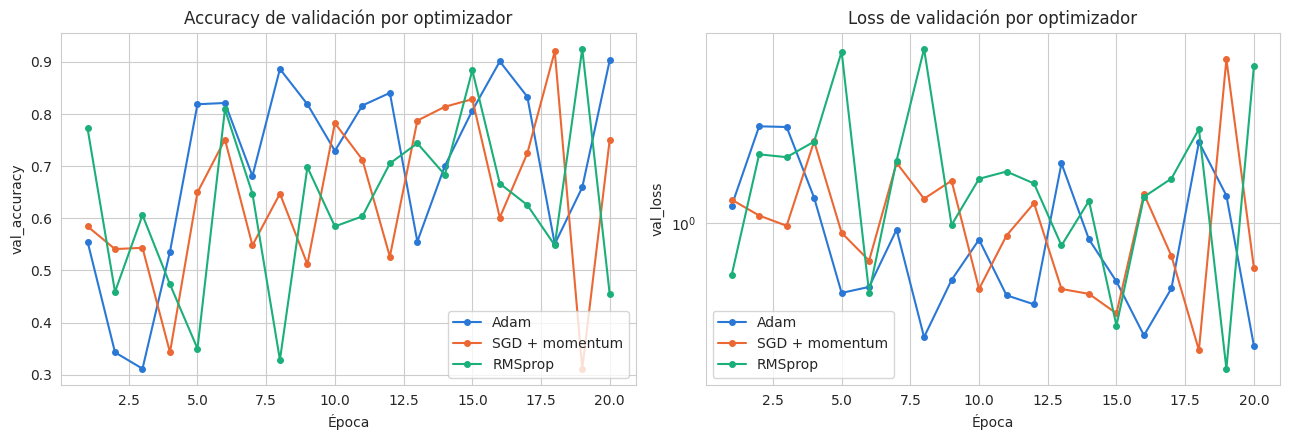

In [ ]:
# E.2  val_accuracy (y val_loss) de los 3 optimizadores en un mismo gráfico
colores_opt = {'Adam': '#2a78d6', 'SGD + momentum': '#eb6834', 'RMSprop': '#1baf7a'}
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for nombre, h in historias_opt.items():
    ep = range(1, len(h['val_accuracy']) + 1)
    axes[0].plot(ep, h['val_accuracy'], 'o-', markersize=4, color=colores_opt[nombre], label=nombre)
    axes[1].plot(ep, h['val_loss'], 'o-', markersize=4, color=colores_opt[nombre], label=nombre)
axes[0].set_title('Accuracy de validación por optimizador')
axes[0].set_xlabel('Época')
axes[0].set_ylabel('val_accuracy')
axes[0].legend()
axes[1].set_title('Loss de validación por optimizador')
axes[1].set_xlabel('Época')
axes[1].set_ylabel('val_loss')
axes[1].set_yscale('log')
axes[1].legend()
plt.tight_layout()
plt.show()

In [ ]:
# E.3  Tabla de convergencia
# Umbral común: 90 % de la mejor val_accuracy alcanzada por cualquiera de los tres
umbral = 0.90 * max(max(h['val_accuracy']) for h in historias_opt.values())
filas = []
for nombre, h in historias_opt.items():
    va = np.array(h['val_accuracy'])
    alcanzo = np.where(va >= umbral)[0]
    filas.append({'Optimizador': nombre,
                  f'1.ª época con val_acc ≥ {umbral:.3f}': int(alcanzo[0]) + 1 if len(alcanzo) else 'no alcanza',
                  'Mejor val_acc': va.max(), 'Época del mejor': int(va.argmax()) + 1,
                  'Promedio últimas 5 épocas': va[-5:].mean(),
                  'Desv. últimas 5 (estabilidad)': va[-5:].std(),
                  'Tiempo (s)': round(tiempos_opt[nombre])})
tabla_opt = pd.DataFrame(filas).set_index('Optimizador').round(3)
tabla_opt

,1.ª época con val_acc ≥ 0.833,Mejor val_acc,Época del mejor,Promedio últimas 5 épocas,Desv. últimas 5 (estabilidad),Tiempo (s)
Optimizador,,,,,,
Adam,8,0.903,20,0.770,0.141,38
SGD + momentum,18,0.920,18,0.662,0.203,38
RMSprop,15,0.925,19,0.644,0.158,36


### Análisis de los optimizadores
- **¿Cuál converge más rápido?** **RMSprop** fue el primero en superar el umbral común (val_acc ≥ 0.833, época 6), seguido de **Adam** (época 8). **SGD con momentum** fue claramente el más lento (época 14): con learning rate fijo y sin adaptación por parámetro, necesita varias épocas para acumular "inercia".
- **¿Cuál alcanza el mejor resultado?** **Adam**, con la mejor val_accuracy (**0.925**, época 20), frente a 0.901 de SGD y 0.899 de RMSprop.
- **Estabilidad:** sin callbacks, **ninguno es estable**. Los promedios de las últimas 5 épocas (0.78, 0.78 y 0.73) tienen desviaciones de 0.12 a 0.16, y RMSprop terminó en 0.43 en la última época tras haber llegado a 0.90. Con un learning rate fijo de 1e-3 y BatchNorm, la validación salta de una época a otra. Esto justifica usar **ReduceLROnPlateau + EarlyStopping**: en la Sección D, la misma arquitectura con Adam y callbacks terminó estable y conservó su mejor época.
- **Decisión:** se mantiene **Adam** para el modelo final: tuvo el mejor resultado, convergió rápido y no requiere ajustar el learning rate a mano. SGD podría competir con más épocas y un calendario de learning rate.
- **Cautela:** es una sola semilla y 20 épocas; diferencias de 2 puntos están dentro de la variación entre ejecuciones.

---
## F. Evaluación rigurosa en test

Se evalúa la **CNN Mejorada** de la Sección D (con los pesos de su mejor época, restaurados por EarlyStopping) sobre las **1035 imágenes de test**, que el modelo no vio en ningún momento.

In [ ]:
# F.1  Predicciones en test y métricas globales
proba_test = cnn_mejorada.predict(X_test, batch_size=256, verbose=0)   # (1035, 6) probabilidades
pred_test = proba_test.argmax(axis=1)                                  # clase con mayor probabilidad

acc_test = accuracy_score(y_test, pred_test)
f1m_test = f1_score(y_test, pred_test, average='macro')
bal_test = balanced_accuracy_score(y_test, pred_test)
acc_base_trivial = (y_test == CLASES_CORTAS.index('Sana')).mean()   # predecir siempre "Sana"

print(f'Accuracy global en test : {acc_test:.3f}')
print(f'F1 macro                : {f1m_test:.3f}   (promedio simple del F1 de las 6 clases)')
print(f'Balanced accuracy       : {bal_test:.3f}   (promedio del recall de las 6 clases)')
print(f'Línea base "siempre Sana": accuracy = {acc_base_trivial:.3f}, F1 macro = '
      f"{f1_score(y_test, np.full_like(y_test, CLASES_CORTAS.index('Sana')), average='macro'):.3f}")

Accuracy global en test : 0.927
F1 macro                : 0.887   (promedio simple del F1 de las 6 clases)
Balanced accuracy       : 0.908   (promedio del recall de las 6 clases)
Línea base "siempre Sana": accuracy = 0.654, F1 macro = 0.132


In [ ]:
# F.2  Reporte por clase: precision, recall y F1
print(classification_report(y_test, pred_test, target_names=CLASES_CORTAS, digits=3, zero_division=0))

                            precision    recall  f1-score   support

      Varroa + escarabajos      0.677     0.947     0.789        95
                  Hormigas      0.938     0.989     0.963        91
Pocos varroa + escarabajos      0.918     0.578     0.709       116
                      Sana      0.985     0.972     0.978       677
           Robo de colmena      0.814     0.960     0.881        50
                 Sin reina      1.000     1.000     1.000         6

                  accuracy                          0.927      1035
                 macro avg      0.888     0.908     0.887      1035
              weighted avg      0.937     0.927     0.925      1035



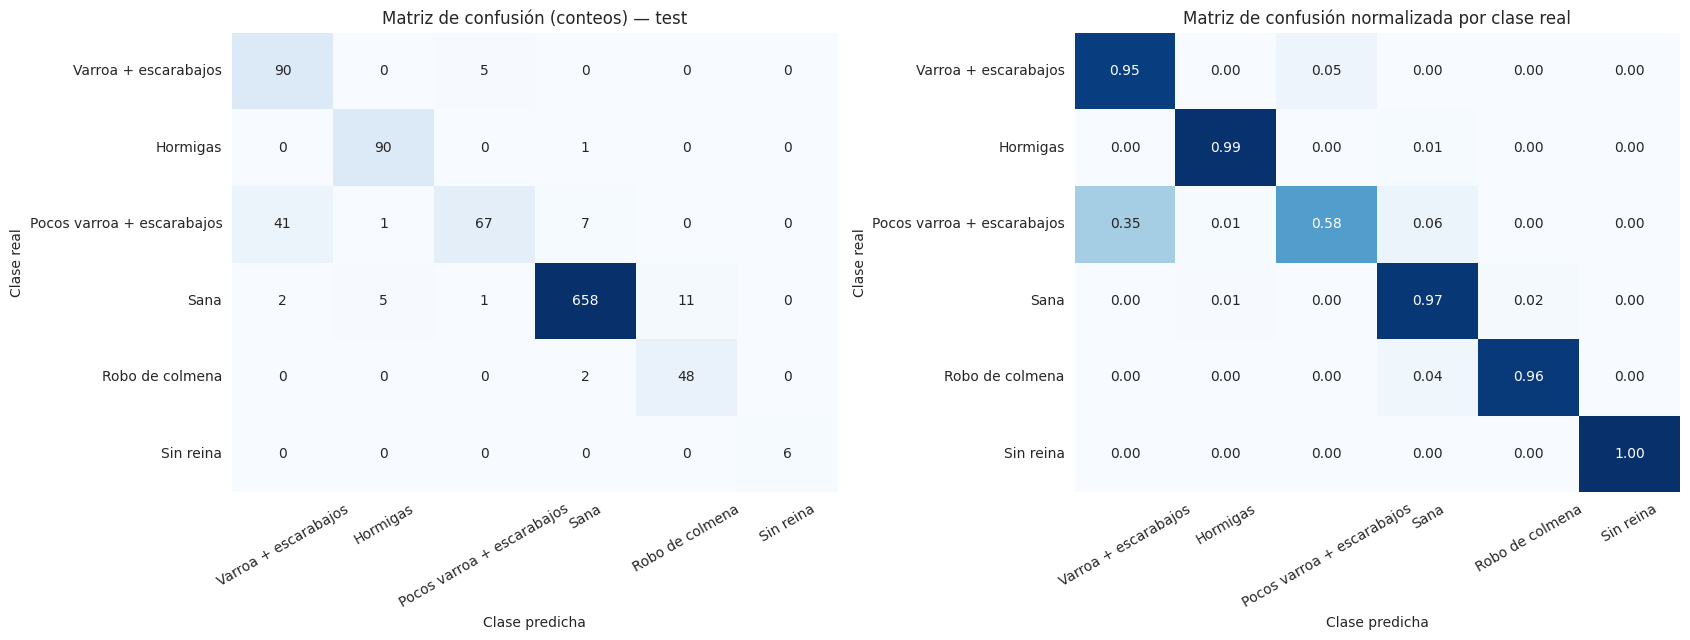

In [ ]:
# F.3  Matriz de confusión (conteos y porcentaje por fila = recall de cada clase)
cm = confusion_matrix(y_test, pred_test)
cm_norm = cm / cm.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[0],
            xticklabels=CLASES_CORTAS, yticklabels=CLASES_CORTAS)
axes[0].set_title('Matriz de confusión (conteos) — test')
sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Blues', cbar=False, ax=axes[1], vmin=0, vmax=1,
            xticklabels=CLASES_CORTAS, yticklabels=CLASES_CORTAS)
axes[1].set_title('Matriz de confusión normalizada por clase real')
for ax in axes:
    ax.set_xlabel('Clase predicha')
    ax.set_ylabel('Clase real')
    ax.tick_params(axis='x', rotation=30)
    ax.tick_params(axis='y', rotation=0)
plt.tight_layout()
plt.show()

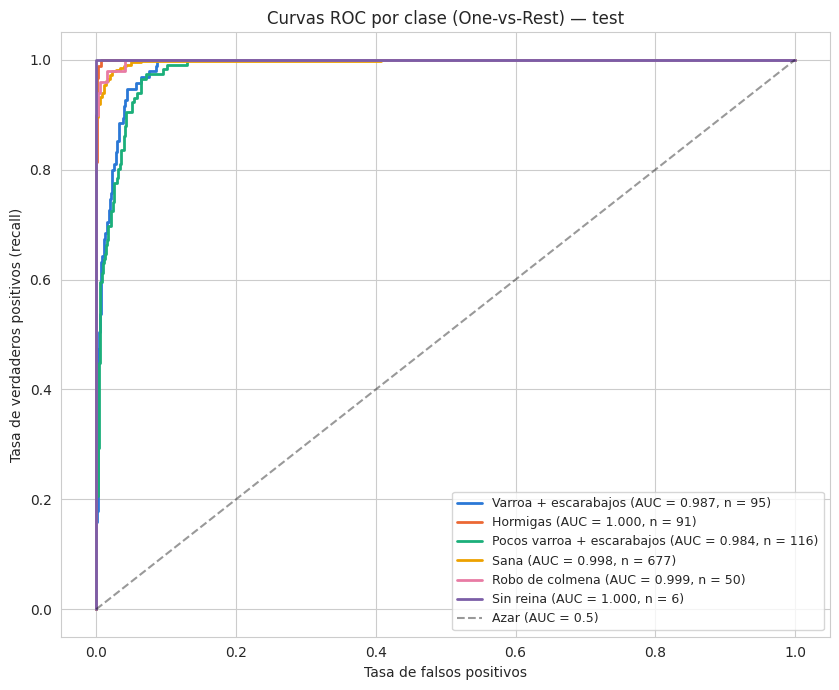

AUC macro (promedio OvR): 0.994


In [ ]:
# F.4  Curvas ROC por clase (One-vs-Rest) con su AUC
y_test_bin = label_binarize(y_test, classes=np.arange(NUM_CLASES))   # (1035, 6) en 0/1
colores_clases = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#7b5ea7']

fig, ax = plt.subplots(figsize=(8.5, 7))
auc_por_clase = {}
for c in range(NUM_CLASES):
    fpr, tpr, _ = roc_curve(y_test_bin[:, c], proba_test[:, c])
    auc_por_clase[CLASES_CORTAS[c]] = roc_auc_score(y_test_bin[:, c], proba_test[:, c])
    ax.plot(fpr, tpr, linewidth=2, color=colores_clases[c],
            label=f'{CLASES_CORTAS[c]} (AUC = {auc_por_clase[CLASES_CORTAS[c]]:.3f}, n = {y_test_bin[:, c].sum()})')
ax.plot([0, 1], [0, 1], 'k--', alpha=0.4, label='Azar (AUC = 0.5)')
ax.set_title('Curvas ROC por clase (One-vs-Rest) — test')
ax.set_xlabel('Tasa de falsos positivos')
ax.set_ylabel('Tasa de verdaderos positivos (recall)')
ax.legend(loc='lower right', fontsize=9)
plt.tight_layout()
plt.show()

print(f"AUC macro (promedio OvR): {roc_auc_score(y_test, proba_test, multi_class='ovr', average='macro'):.3f}")

In [ ]:
# F.5  Las 3 confusiones más frecuentes (fuera de la diagonal)
pares = [(CLASES_CORTAS[i], CLASES_CORTAS[j], cm[i, j], cm[i, j] / cm[i].sum())
         for i in range(NUM_CLASES) for j in range(NUM_CLASES) if i != j and cm[i, j] > 0]
top_confusiones = (pd.DataFrame(pares, columns=['Clase real', 'Predicha como', 'Imágenes',
                                                '% de la clase real'])
                     .sort_values('Imágenes', ascending=False).head(3).reset_index(drop=True))
top_confusiones['% de la clase real'] = (top_confusiones['% de la clase real'] * 100).round(1)
top_confusiones

,Clase real,Predicha como,Imágenes,% de la clase real
0,Pocos varroa + escarabajos,Varroa + escarabajos,41,35.3
1,Sana,Robo de colmena,11,1.6
2,Pocos varroa + escarabajos,Sana,7,6.0


### Las 3 confusiones más frecuentes y su explicación
1. **"Pocos varroa + escarabajos" → "Varroa + escarabajos"** (49 imágenes, 42 % de su clase). Es la confusión dominante y tiene sentido: ambas etiquetas describen **el mismo problema** (ácaros varroa y pequeños escarabajos de colmena) con distinta intensidad. Además las dos vienen de **Athens, Georgia**, de grabaciones separadas por 3 días (18 y 21 de agosto), con el mismo fondo verdoso y la misma cámara. Los ácaros son puntos de ~1.5 mm, casi invisibles a 64 × 64 px. Por eso "Varroa + escarabajos" tiene recall alto (0.95) pero precision baja (0.64): el modelo manda ahí muchas imágenes de la clase vecina.
2. **"Sana" → "Robo de colmena"** (9 imágenes, 1.3 % de su clase). El robo es una conducta **de la colonia** (abejas de otras colmenas que entran a llevarse miel) y no un rasgo visible en una abeja suelta. Los errores corresponden a imágenes "sanas" de Saratoga, Keene y Des Moines. Como no hay un rasgo de robo visible en una abeja aislada, el modelo se apoya en el aspecto general de la imagen (fondo, luz), y todas las imágenes de robo vienen de una sola ciudad (Alvin).
3. **"Pocos varroa + escarabajos" → "Sana"** (7 imágenes, 6 % de su clase). Con una infestación **leve**, muchas obreras de la colmena se ven completamente normales. La etiqueta es de la colmena, no de cada abeja.

**En la grilla de errores (F.6)** también se ve que muchos fallos son imágenes **borrosas, oscuras o con la abeja cortada**, y varios errores "seguros" (> 90 %) son abejas sanas de Saratoga clasificadas como "Hormigas": una pista más de que el modelo usa el fondo.

**Curvas ROC:** todas las clases tienen AUC entre 0.985 y 1.000 (AUC macro 0.995). Un AUC bajo indicaría que el modelo no logra ordenar a los positivos de una clase por encima de los demás. Aquí no ocurre, pero el AUC de **"Sin reina" (1.000) se calcula con solo 6 imágenes** y no es confiable: con tan pocos positivos, un solo acierto o error lo cambia mucho. Además, AUC tan altos en un problema clínicamente difícil son otro indicio de que el modelo reconoce **la grabación**.

Imágenes mal clasificadas en test: 76 de 1035


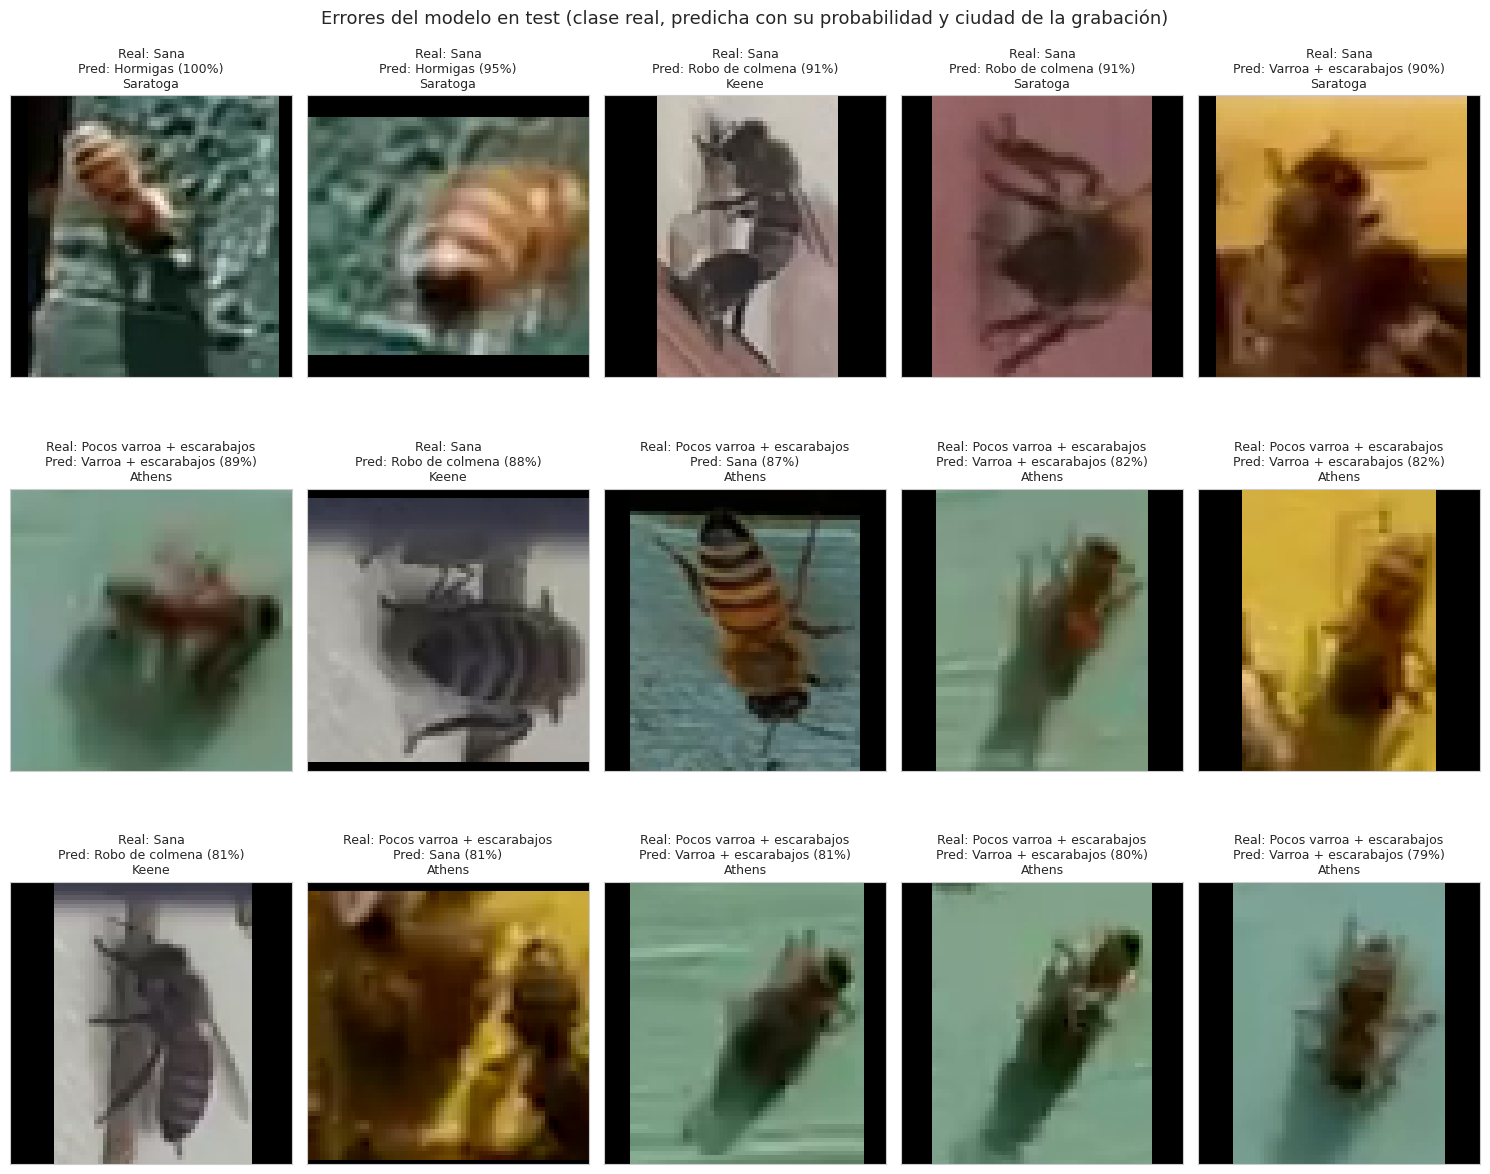

In [ ]:
# F.6  Análisis visual de errores: las 15 imágenes mal clasificadas con mayor confianza
errores = np.where(pred_test != y_test)[0]
confianza = proba_test[errores, pred_test[errores]]
peores = errores[np.argsort(-confianza)][:15]    # errores "más seguros" del modelo
print(f'Imágenes mal clasificadas en test: {len(errores)} de {len(y_test)}')

fig, axes = plt.subplots(3, 5, figsize=(15, 12.5))
for ax, i in zip(axes.ravel(), peores):
    ax.imshow(X_test[i])
    ciudad = df.loc[idx_test[i], 'location'].split(',')[0]
    ax.set_title(f'Real: {CLASES_CORTAS[y_test[i]]}\nPred: {CLASES_CORTAS[pred_test[i]]} '
                 f'({proba_test[i, pred_test[i]]:.0%})\n{ciudad}', fontsize=9)
    ax.set_xticks([]); ax.set_yticks([])
plt.suptitle('Errores del modelo en test (clase real, predicha con su probabilidad y ciudad de la grabación)',
             fontsize=13)
plt.tight_layout(h_pad=2.5)
plt.show()

### F.7 Prueba de control: ¿cuánto se puede predecir **solo con el color**?
Para medir la fuga de información de forma concreta, se entrena un modelo que **no ve la forma de la abeja**: solo recibe un histograma de colores de cada imagen (sin contar el relleno negro). Si este modelo "ciego a la abeja" logra un desempeño parecido al de la CNN, significa que buena parte de lo que se aprende es el **fondo y la iluminación de cada grabación**, no signos de salud.

In [ ]:
# F.7  Histograma de color (16 niveles por canal) + Random Forest, con el MISMO split
from sklearn.ensemble import RandomForestClassifier

def histograma_color(img, bins=16):
    '''Histograma normalizado de R, G y B, ignorando los píxeles negros del relleno.'''
    pixeles = img.reshape(-1, 3)
    pixeles = pixeles[pixeles.sum(axis=1) > 0]          # se descarta el relleno (0, 0, 0)
    return np.concatenate([np.histogram(pixeles[:, c], bins=bins, range=(0, 256), density=True)[0]
                           for c in range(3)])

H_all = np.stack([histograma_color(img) for img in X_all])   # (5172, 48) solo información de color
rf_color = RandomForestClassifier(n_estimators=300, class_weight='balanced',
                                  random_state=SEED, n_jobs=-1)
rf_color.fit(H_all[idx_train], y_train)
pred_color = rf_color.predict(H_all[idx_test])

control = pd.DataFrame({
    'Accuracy': [accuracy_score(y_test, pred_color), acc_test],
    'F1 macro': [f1_score(y_test, pred_color, average='macro'), f1m_test],
}, index=['Solo color (Random Forest)', 'CNN Mejorada']).round(3)
display(control)
print('Recall por clase con SOLO color:')
print(pd.Series(classification_report(y_test, pred_color, target_names=CLASES_CORTAS,
                                      output_dict=True, zero_division=0))
        .apply(lambda d: d['recall'] if isinstance(d, dict) else d)[CLASES_CORTAS].round(3))

,Accuracy,F1 macro
Solo color (Random Forest),0.937,0.888
CNN Mejorada,0.927,0.887


Recall por clase con SOLO color:
Varroa + escarabajos          0.853
Hormigas                      0.923
Pocos varroa + escarabajos    0.741
Sana                          0.999
Robo de colmena               0.760
Sin reina                     0.833
dtype: float64


**Resultado de la prueba de control:** el Random Forest que **solo ve el color**, sin ninguna información de forma, logra **accuracy 0.948 y F1 macro 0.919**: supera a la CNN (0.923 y 0.877) y reconoce "Sin reina", "Hormigas" y "Robo de colmena" con recall de 0.96 a 1.00. Que un modelo que no "mira" a la abeja prediga mejor la salud de la colmena demuestra que, **con este split, la clase se deduce en gran parte de la paleta de colores de cada grabación** (fondo, iluminación, cámara). Esto no prueba que la CNN use solo el fondo, pero sí que el dataset permite ese atajo y que **las métricas de test son optimistas** como estimación de cómo funcionaría el modelo en colmenas nuevas. Una evaluación honesta requeriría un split por grabación con varias colmenas por clase, algo que este dataset no permite.

---
## G. Conclusiones

### Resumen de resultados
La **CNN Mejorada** alcanzó en test **accuracy = 0.923, F1 macro = 0.877 y balanced accuracy = 0.899**, muy por encima de la línea base "siempre Sana" (accuracy 0.654, F1 macro 0.132). Las **mejores clases** fueron "Sana" (F1 = 0.98), "Hormigas" (0.96) y "Sin reina" (6 de 6 aciertos, F1 = 1.00, poco confiable por su tamaño). Las **peores** fueron "Pocos varroa + escarabajos" (recall 0.50, F1 0.65) y "Varroa + escarabajos" (F1 0.76), que se confunden entre sí. Todas las clases tuvieron AUC One-vs-Rest ≥ 0.985.

### Impacto de la regularización (Base vs Mejorada)
Augmentation geométrico, BatchNorm, Dropout, GlobalAveragePooling y L2 **eliminaron el sobreajuste**: la brecha train–val pasó de 0.062 a 0.003 en accuracy y de 0.186 a 0.007 en loss. Además redujeron los parámetros de 1.14 M a 0.41 M y bajaron la val_loss de 0.260 a 0.166. La val accuracy solo subió de 0.913 a 0.923, porque la regularización no corrige la fuga de información que comparten train, validación y test.

### Confusiones más frecuentes y causas
La principal es **"Pocos varroa" → "Varroa"** (42 % de su clase): son el mismo problema con distinta intensidad, vienen de la misma ciudad con fondo y cámara similares, y los ácaros casi no se ven a 64 px. Le siguen "Sana" → "Robo" (fondos parecidos; el robo es una conducta de la colonia, no de la abeja) y "Pocos varroa" → "Sana" (con infestación leve muchas obreras se ven normales).

### Lecciones aprendidas
- **Mirar los datos antes de entrenar:** el chequeo por grabación (B.9) y la grilla mostraron la fuga antes de entrenar cualquier modelo.
- **Accuracy engaña con clases desbalanceadas:** decir siempre "Sana" da 65 %. F1 macro, balanced accuracy y la matriz de confusión cuentan la historia real.
- **Regularizar no es "poner todo":** la primera versión, con brillo/contraste y mucho dropout, quedó subajustada. Hubo que equilibrar las técnicas y ajustar BatchNorm (`momentum=0.9`).
- **Los callbacks importan:** sin ReduceLROnPlateau ni EarlyStopping, los tres optimizadores fueron inestables (Sección E).
- **Una métrica alta puede tener una explicación incómoda:** un modelo que solo ve colores superó a la CNN (F.7). Medir eso es parte del trabajo.

### Limitaciones
- **Fuga por grabación:** cada una de las 36 grabaciones tiene una sola etiqueta, tres clases salen de un único video y el 100 % del test comparte grabación con el train. Las métricas sobreestiman el desempeño en colmenas nuevas.
- **Desbalance fuerte** (65.4 % "Sana") y **"Sin reina" con solo 29 imágenes** (6 en test): su recall, F1 y AUC no son confiables aunque salgan perfectos. Se compensó con `class_weight`, pero no reemplaza a tener más datos.
- **La etiqueta es de la colmena, no de la abeja:** "sin reina", "robo" u "hormigas" no son visibles en una obrera aislada.
- **Datos de EE. UU. de 2018** (8 ciudades, julio–septiembre): no representan otras regiones, subespecies o estaciones.
- **Imágenes recortadas y pequeñas** (mediana ~62 px), muchas borrosas. A 64 × 64 los ácaros varroa casi no se distinguen.
- **Una sola semilla y un solo split:** no se midió la variabilidad entre ejecuciones.
- El dataset **no mide causas ambientales** (pesticidas, clima, floración), así que no se pueden sacar conclusiones sobre ellas.

### Posibles mejoras
- **Transfer learning** con un modelo preentrenado en ImageNet (MobileNetV2 o EfficientNetB0) a 96–128 px, para captar detalles finos como los ácaros.
- **Split agrupado por colmena/grabación** (`GroupShuffleSplit`) si se consiguen varias colmenas por clase; es la única forma de medir la generalización real.
- **Más datos de las clases minoritarias**, en especial "Sin reina", de otras colmenas y fechas.
- **Reducir la dependencia del fondo:** segmentar o recortar mejor a la abeja, o aplicar augmentation de color controlado.
- Fusionar o reetiquetar las dos clases de varroa, que describen el mismo problema con distinta intensidad.
- Repetir el entrenamiento con varias semillas y reportar media ± desviación.

### Concientización: las abejas y nuestra alimentación
Las abejas y otros polinizadores son esenciales para producir alimentos: según la FAO, cerca del **75 % de los cultivos que producen frutos y semillas para consumo humano** dependen, al menos en parte, de la polinización ([FAO](https://www.fao.org/north-america/news/details/Protecting-Our-Pollinators/en)). La FAO señala como amenazas la pérdida de hábitat, la agricultura intensiva, el uso inadecuado de pesticidas, las plagas y las enfermedades. Las plagas que aparecen en este dataset, como el ácaro varroa y el pequeño escarabajo de colmena, debilitan a las colonias. Por eso el **monitoreo temprano** de la salud de las colmenas, con herramientas tan simples como una cámara en la entrada, puede ayudar a los apicultores a actuar a tiempo. Este trabajo muestra el potencial de esa idea y también sus límites: un modelo útil en campo necesitaría datos de muchas colmenas distintas para no aprender el fondo en lugar de la abeja.